# Week 09: Hypothesis testing in Python

**Course:** MATH7810 Python for Data Science (AY2026/27)

## Hypothesis Testing



In [2]:
# Load libraries
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats      # scipy is the most commonly used package for conductiong hypothesis

In [3]:
# Load data
order = pd.read_csv('checkout.csv')
order.head()

   index  user_id checkout_page  ...  gender  browser time_on_page
0      0   877621             A  ...       F   chrome    66.168628
1      1   876599             A  ...       M  firefox    49.801887
2      2   905407             A  ...       M   chrome    56.744856
3      3   883562             A  ...       M   safari    71.890718
4      4   840542             A  ...       F   safari    67.410696

[5 rows x 8 columns]


In [4]:
print("rows, columns:", order.shape)

rows, columns: (9000, 8)


In [5]:
# Distinct values of the categorical columns only.
# purchased is 0/1, so it is categorical even though it is stored as a number.
categorical = ["checkout_page", "purchased", "gender", "browser"]
print(order[categorical].nunique())

checkout_page    3
purchased        2
gender           2
browser          3
dtype: int64


In [6]:
# Numeric summary: count, mean, standard deviation, minimum, quartiles, and maximum.
# Categorical columns are left out. order_value has a smaller count because it is missing when purchased is 0.
print(order.describe())

             index        user_id  order_value    purchased  time_on_page
count  9000.000000    9000.000000  7605.000000  9000.000000   9000.000000
mean   4499.500000  874671.107778    30.027170     0.845000     43.205357
std    2598.220545   23152.083012    10.406407     0.361925     10.444232
min       0.000000  834528.000000     0.030000     0.000000      7.597721
25%    2249.750000  854533.750000    22.670000     1.000000     35.942253
50%    4499.500000  874657.500000    29.910000     1.000000     43.149846
75%    6749.250000  894669.500000    36.990000     1.000000     50.181631
max    8999.000000  914582.000000    64.130000     1.000000     83.051697


In [7]:
# Mean time on page, in minutes, for each checkout page.
order.groupby('checkout_page')['time_on_page'].mean()

checkout_page
A    44.668527
B    42.723772
C    42.223772
Name: time_on_page, dtype: float64


## 9.1 One-sample t-test

When the population standard deviation is unknown, t-test is preferred compared to z-test.

$H_0$: The average time all users spend on the checkout page "A" is equal to 44 minutes.     
$H_1$: The average time all users spend on the checkout page "A" is NOT equal to 44 minutes.

In [10]:
from scipy import stats  

# Population Mean 
mu = 44

# Page A only. The value 44 is the mean under H0, not a generated sample.
time_on_page_A = order[order['checkout_page'] == 'A']['time_on_page']
print(f"sample mean: {time_on_page_A.mean():.4f}, n={len(time_on_page_A)}")

t_stat, p_val = stats.ttest_1samp(time_on_page_A, popmean = mu)
print(f"t-statistic: {t_stat:.4f}, p-value: {p_val:.4f}, n={len(time_on_page_A)}")

sample mean: 44.6685, n=3000
t-statistic: 3.1443, p-value: 0.0017, n=3000


We set $\alpha = 0.05$. Given p-value is less than 0.05, we reject the null hypothesis and conclude that the average time all users spend on the checkout page "A" is significantly different from 44 minutes.   

We then try to test the following hypothesis:    
$H_0$: The average time all users spend on the checkout page "A" is equal to 45 minutes.     
$H_1$: The average time all users spend on the checkout page "A" is NOT equal to 45 minutes.

In [12]:
from scipy.stats import ttest_1samp

t_stat, p_value = ttest_1samp(time_on_page_A, popmean=45, alternative='two-sided')
print(f"t-statistic: {t_stat:.4f}, p-value: {p_value:.4f}, n={len(time_on_page_A)}")

t-statistic: -1.5590, p-value: 0.1191, n=3000


Given p-value is greater than 0.05, we fail to reject the null hypothesis and conclude that the evidence is insufficient to support a significant difference between 45 minutes and the average browsing time for those checkout page is "A", given the data and the test's power.

## 9.2 Two-sample t-test

Now let us check whether there is any significant difference between the time on page if users checkout from page A and B. Let $\mu_A$ denote the average browsing time of all users if the checkout page is A. Similarly,  $\mu_B$ denotes the average browsing time of all users if the checkout page is B. 

$H_0:  \mu_A = \mu_B$ $\quad$ vs $\quad$ $H_1:  \mu_A \neq \mu_B$

In [16]:
# Data preparation
time_on_page_A = order[order['checkout_page'] == 'A']['time_on_page']
time_on_page_B = order[order['checkout_page'] == 'B']['time_on_page']
time_on_page_C = order[order['checkout_page'] == 'C']['time_on_page']

print(f"sample mean A: {time_on_page_A.mean():.4f}, n={len(time_on_page_A)}")
print(f"sample mean B: {time_on_page_B.mean():.4f}, n={len(time_on_page_B)}")
print(f"sample mean C: {time_on_page_C.mean():.4f}, n={len(time_on_page_C)}")

sample mean A: 44.6685, n=3000
sample mean B: 42.7238, n=3000
sample mean C: 42.2238, n=3000


In [17]:
from scipy.stats import ttest_ind
tstat, pval = ttest_ind(time_on_page_A, time_on_page_B)
print(f"T-statistic: {tstat:.4f}, p-value: {pval:.4f}")

T-statistic: 7.0267, p-value: 0.0000


Given p-value is less than 0.05, we reject the null hypothesis and conclude that the average time all users spend on the checkout page "A" and "B" is significantly different.   

The two-sample t-test compares the population means of two independent groups. Chapter 5 uses it when these conditions hold:

1. The two samples are independent.
2. The population standard deviations are unknown, so the test uses a t distribution. When those two standard deviations can be treated as equal, use the pooled t-test above. When they are unequal, use Welch's t-test below.
3. Both sample sizes are at least 30, or a smaller sample comes from a normal population. Here $n_A = n_B = 3000$, so the large-sample condition applies.

In [20]:
# Compare the sample standard deviations to choose the pooled or the unequal-variance t-test.
print(f"sample sd A: {time_on_page_A.std(ddof=1):.4f}")
print(f"sample sd B: {time_on_page_B.std(ddof=1):.4f}")

sample sd A: 11.6456
sample sd B: 9.7047


In [21]:
# The sample standard deviations differ, so use the unequal-variance t-test.
tstat, pval = ttest_ind(time_on_page_A, time_on_page_B, equal_var=False)
print(f"Welch's t-test: {tstat:.4f}, p-value: {pval:.4f}")

Welch's t-test: 7.0267, p-value: 0.0000


Welch's t-test and the pooled t-test agree to four decimal places. Both sample sizes are 3000, so the two formulas give nearly the same result. Both p-values are less than 0.05, and the conclusion is unchanged.

## 9.3 Two-sample z-test for population proportion

Now we would like to answer the question:    
Is the purchase proportion of users using the Chrome browser the same as that of users using the Firefox browser?

$H_0: p_c = p_f$ $\quad$ vs $\quad$ $H_1: p_c \neq p_f$

In [25]:
from statsmodels.stats.proportion import proportions_ztest

# Count the purchase of Chrome and Firefox users & total number of users
purchase_chrome = order[order['browser'] == 'chrome']['purchased'].sum()
total_chrome = len(order[order['browser'] == 'chrome'])

# Sample proportion of Chrome user
print(f"sample proportion of purchase in Chrome user: {purchase_chrome/total_chrome:.4f}")

purchase_firefox = order[order['browser'] == 'firefox']['purchased'].sum()
total_firefox = len(order[order['browser'] == 'firefox'])

# Sample proportion of Firefox user
print(f"sample proportion of purchase in Firefox user: {purchase_firefox/total_firefox:.4f}")

# z test for population proportion
count = np.array([purchase_chrome, purchase_firefox])
nobs = np.array([total_chrome, total_firefox])
z_stat, p_value = proportions_ztest(count, nobs)
print(f"Z-statistic: {z_stat:.4f}, p-value: {p_value:.4f}")

sample proportion of purchase in Chrome user: 0.8391
sample proportion of purchase in Firefox user: 0.8517
Z-statistic: -1.3434, p-value: 0.1792


Given the p-value is greater than 0.05, we fail to reject the null hypothesis and claim that that the evidence is insufficient to support a significant difference of proportion of purchase between different browswer users, given the data and the test's power.

## 9.4 Analysis of variance (ANOVA)

We could also test whether **at least one** checkout page has a different average time on page for its users. Let $\mu_1,\mu_2,\mu_3$ denote the average time on page for different checkout page.   

$H_0:  \mu_1 = \mu_2 = \mu_3 $ $\quad$ vs $\quad$ $H_1:\text{not all three population means are equal}$.

In [29]:
# Each page has n = 3000, so the large-sample condition applies.
from scipy.stats import f_oneway
f_stat, p_value = f_oneway(time_on_page_A, time_on_page_B, time_on_page_C)
print(f"F-statistic: {f_stat:.4f}, p-value: {p_value:.4f}")

F-statistic: 46.3402, p-value: 0.0000


Given that p-value is less than 0.05, we reject the null hypothesis and claimed that not all three population means are equal.      
ANOVA is beyond the core of MATH7810; a dedicated regression course covers it in more depth.


## 9.5 Pearson Correlation Test

This test assesses the strength and direction of the **linear relationship** between two **continuous** variables. 

$H_0: \text{There is no linear correlation between the order value and time on page, } \rho = 0$ $\quad$ vs $\quad$ 

$H_1:\text{There is linear correlation between the two variables, } \rho \neq 0$ 

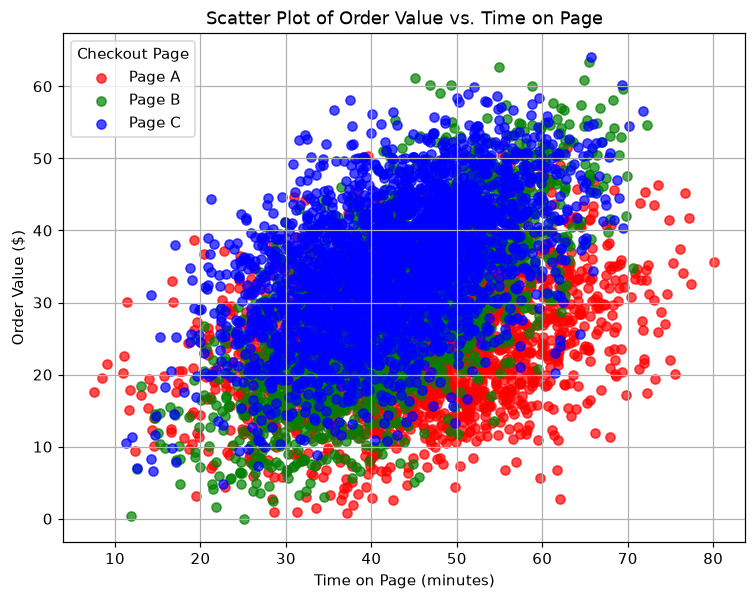

In [33]:
order_clean = order.dropna()

# Define a color map for the checkout_page categories
colors = {'A': 'red', 'B': 'green', 'C': 'blue'}

# Create a scatter plot
plt.figure(figsize=(8, 6))

# Plot each category with a different color
for page in order_clean['checkout_page'].unique():
    subset = order_clean[order_clean['checkout_page'] == page]
    plt.scatter(subset['time_on_page'], subset['order_value'], 
                color=colors[page], label=f'Page {page}', alpha=0.7)

plt.title('Scatter Plot of Order Value vs. Time on Page')
plt.xlabel('Time on Page (minutes)')
plt.ylabel('Order Value ($)')
plt.grid(True)
plt.legend(title='Checkout Page')
plt.show()

In [34]:
from scipy.stats import pearsonr #, spearmanr

# To keep only the purchased samples
order_clean = order.dropna(subset=['order_value', 'time_on_page'])

# Run the test
pearson_corr, pearson_p = pearsonr(order_clean['time_on_page'], order_clean['order_value']) 

# Output the results with four decimal places
print(f"Pearson Correlation Coefficient: {pearson_corr:.4f}, p-value: {pearson_p:.4f}")

Pearson Correlation Coefficient: 0.4060, p-value: 0.0000


Given p-value is less than 0.05, we reject the null hypothesis and claimed that the correlation coefficient between the time on page and the order value is significantly different from 0.   

Recall Chapter 1: correlation $r$ summarizes linear association. 


## 9.6 Chi-squared test for independence

By adopting the Chi-squared test, we are able to decide whether two **categorical** variables of a population are independent.    
$H_0: \text{gender and purchased are independent}$        
vs 
$\quad$        
$H_1:\text{gender and purchased are not independent}$

In [38]:
from scipy.stats import chi2_contingency

# Summarize the count in a contingency table
contingency_table_col = pd.crosstab(order['gender'], order['purchased'], normalize='columns')
print("column percentage", contingency_table_col)

contingency_table= pd.crosstab(order['gender'], order['purchased'])
print("contingency_table", contingency_table)

chi2, p, dof, expected = chi2_contingency(contingency_table)
print(f"Chi2 Statistic: {chi2:.4f}, p-value: {p:.4f}")

column percentage purchased         0         1
gender                       
F          0.301075  0.545431
M          0.698925  0.454569
contingency_table purchased    0     1
gender              
F          420  4148
M          975  3457
Chi2 Statistic: 280.6240, p-value: 0.0000


Given that the p-value is less than 0.05, we reject the null hypothesis and conclude that gender and purchased are not independent.    
Logistic regression is beyond MATH7810; mentioned here only as an extension.


## 9.7 Paired-sample t-test

These data represent a study measuring the effect of a new training program on the performance scores of 20 randomly sampled individuals. We would like to know whether the performance score of all participants is significantly improved after taking the training program.   
$H_0: \mu_b = \mu_a$ $\quad$ vs $\quad$ $H_1: \mu_b \neq \mu_a$.

In [42]:
Before = [82, 84, 85, 89, 91, 91, 92, 94, 99, 99,
         105, 109, 109, 109, 110, 112, 112, 113, 114, 114]

After = [90, 91, 91, 91, 95, 95, 99, 99, 108, 109,
         109, 114, 115, 116, 117, 117, 128, 129, 130, 133]

df = pd.DataFrame({'Before': Before, 'After': After})
print(df)

    Before  After
0       82     90
1       84     91
2       85     91
3       89     91
4       91     95
5       91     95
6       92     99
7       94     99
8       99    108
9       99    109
10     105    109
11     109    114
12     109    115
13     109    116
14     110    117
15     112    117
16     112    128
17     113    129
18     114    130
19     114    133


In [43]:
print("mean score (Before):" , np.mean(Before))
print("mean score (After):" , np.mean(After))

from scipy.stats import ttest_rel

# Paired t-test: each person has a before score and an after score.
tstat, pval = ttest_rel(Before, After)

print(f"Paired t-test statistic: {tstat:.4f}, p-value: {pval:.4f}")

mean score (Before): 100.65
mean score (After): 108.8
Paired t-test statistic: -7.5692, p-value: 0.0000


In [44]:
# If we use the independent t-test, which is inappropriate for this example
tstat, pval = ttest_ind(Before, After)

print(f"T-statistic: {tstat:.4f}, p-value: {pval:.4f}")

T-statistic: -1.9953, p-value: 0.0532


The paired t-test has a p-value less than 0.05, so we reject the null hypothesis and conclude that the before and after scores differ.

The independent t-test on the same numbers has a p-value of about 0.053, so it would not reject at $\alpha = 0.05$. That test ignores the pairing, so it is the wrong test for these data.